In [2]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf

import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_deep_learning as udl

from generator import Generator
# import feature_extractor as feature_extractor


pil.SERVER = True

2024-04-04 01:06:41.924211: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-04 01:06:41.924288: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-04 01:06:41.926159: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-04 01:06:41.937203: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-04 01:06:43.149708: W tensorflow/comp

In [3]:
input_shape = (192,224,192)

G = Generator()

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(G=G)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))



2024-04-04 01:06:46.923729: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31141 MB memory:  -> device: 0, name: Tesla V100-PCIE-32GB, pci bus id: 0000:c1:00.0, compute capability: 7.0


In [4]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)

def generate_image(id, G):   
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = G(udl.prepare_img_for_gan(img_hunt3), training=False)
    img_gen = udl.recover_img_from_gan(img_gen)
    return img_hunt3, img_hunt4, img_gen


-------- Checkpoint: 1
ID: 302


2024-04-04 01:06:47.655734: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-04 01:06:47.768600: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-04 01:06:49.494105: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


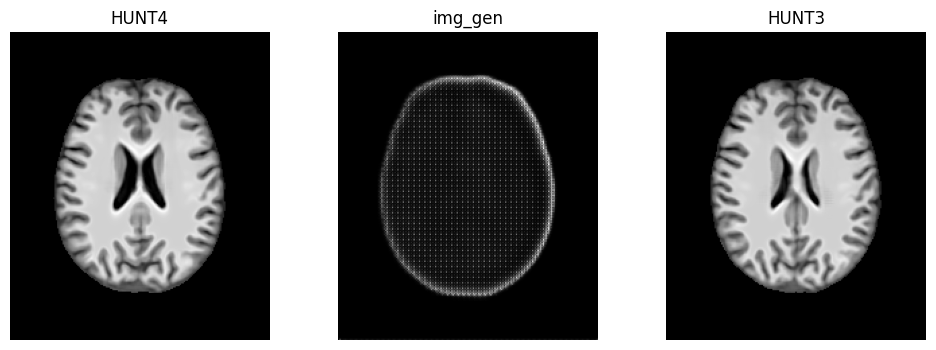

-------- Checkpoint: 2
ID: 302


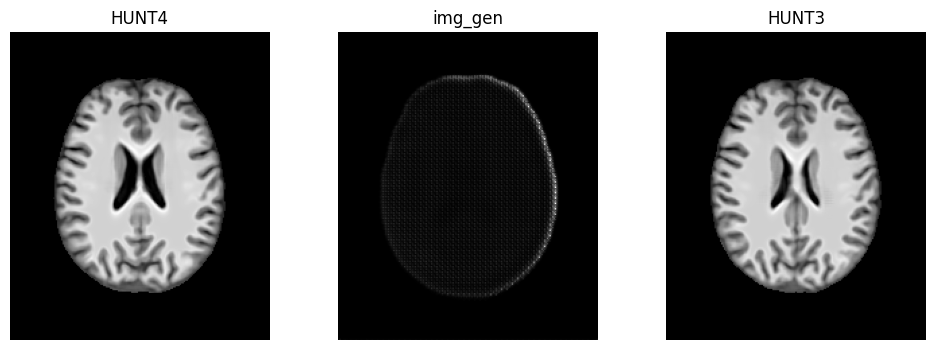

-------- Checkpoint: 3
ID: 302


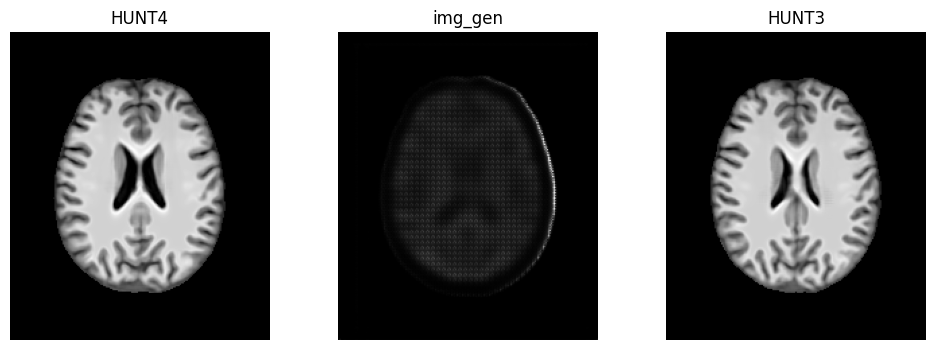

-------- Checkpoint: 4
ID: 302


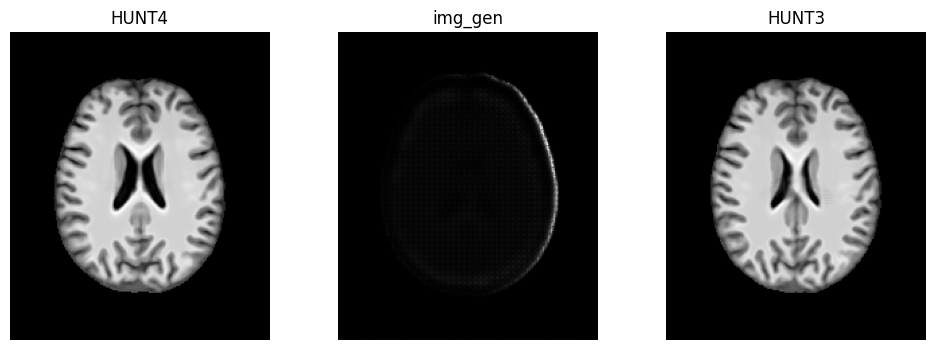

-------- Checkpoint: 5
ID: 302


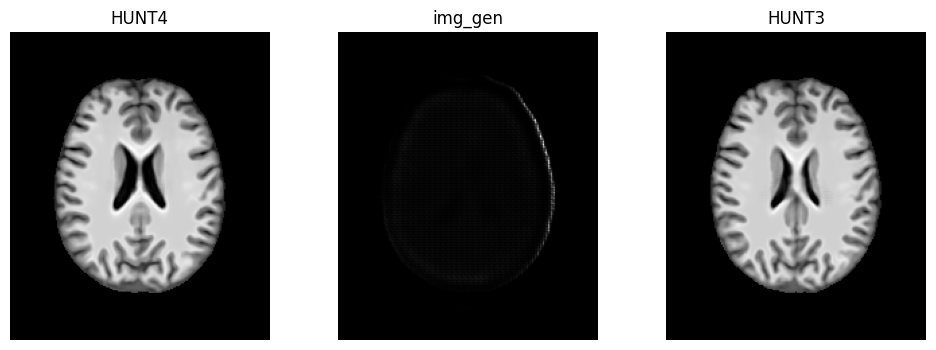

-------- Checkpoint: 6
ID: 302


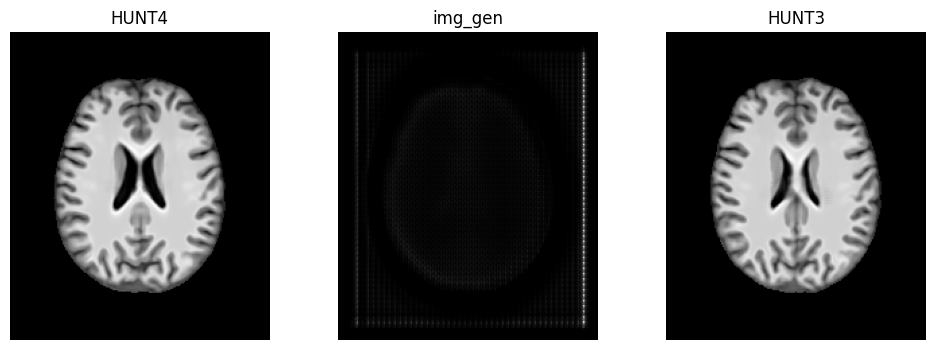

-------- Checkpoint: 7
ID: 302


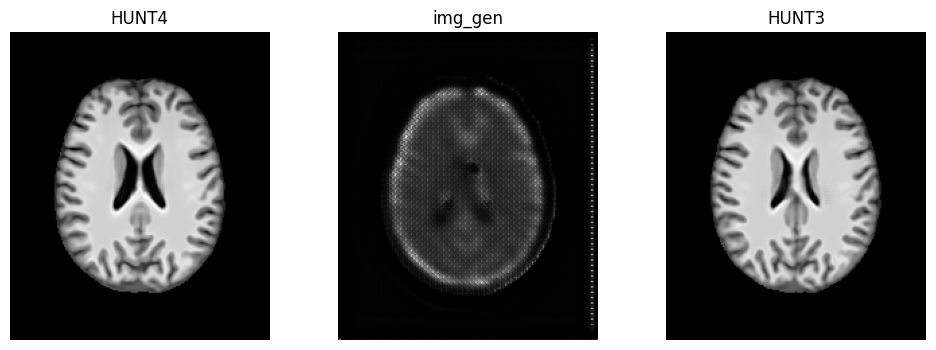

-------- Checkpoint: 8
ID: 302


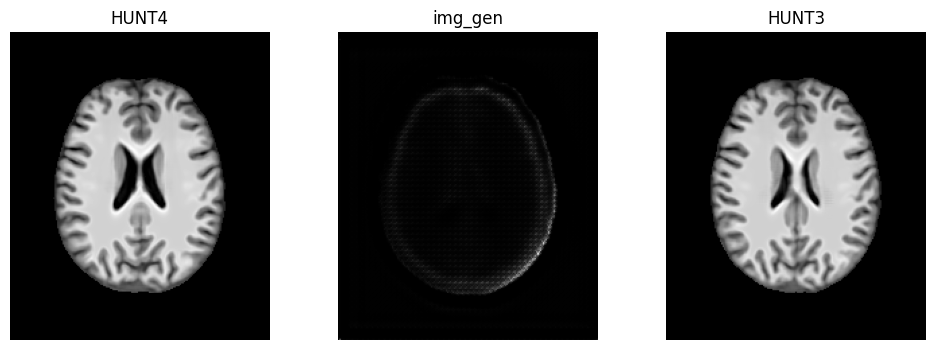

-------- Checkpoint: 9
ID: 302


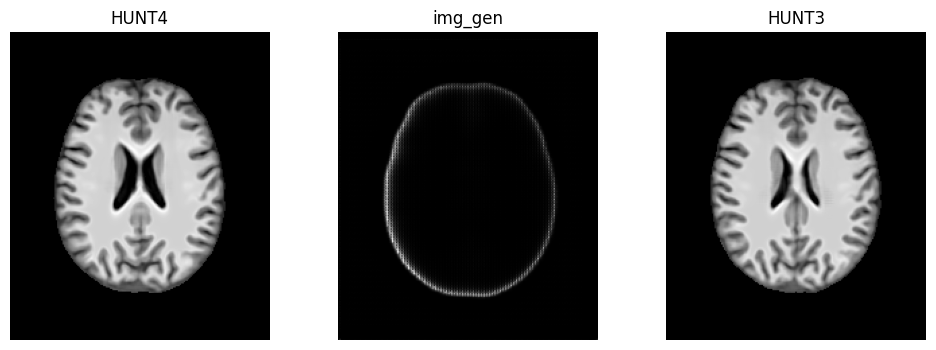

-------- Checkpoint: 10
ID: 302


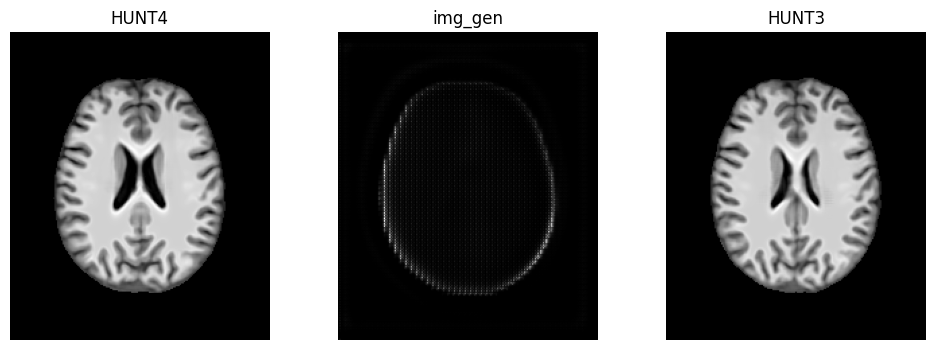

-------- Checkpoint: 11
ID: 302


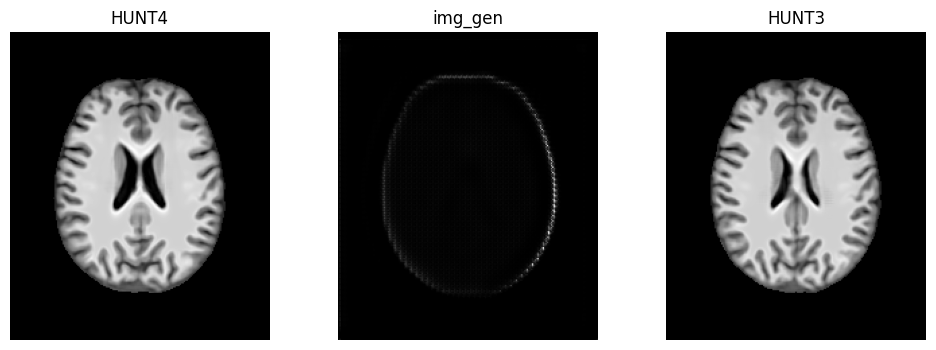

In [5]:
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [302]
images_list = []
for checkpoint_index in range(1, 12, 1):
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    for id_index in id_indexs:
        print(f"ID: {id_index}")
        id = matching_ids[id_index]

        img_hunt3, img_hunt4, img_gen = generate_image(id, G)
        vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

        # save image
        # img_path_name = f"{current_path}/images/first_results/{id}_CHECK_{checkpoint_index}.nii.gz"
        # save_image(id, img_gen, checkpoint_index)

